In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.model_selection import train_test_split

# 0. Re-initialize dataset X from your earlier data generation (mocking your time-series stream if needed)
# If your synthetic data array 'X' is already in memory from an earlier cell, this uses it.
# If not, this recreates a dummy/sample dataset structure matching your 15-sample windows:
if 'X' not in locals():
    print("[INFO] Re-generating sliding window dataset X for classifier...")
    # Generating 1000 synthetic temperature sequences matching your previous setup
    np.random.seed(42)
    base_temps = 22.0 + np.sin(np.linspace(0, 50, 1000)) * 4.0 + np.random.normal(0, 0.2, 1000)
    window_size = 15
    X_list = []
    for i in range(len(base_temps) - window_size):
        X_list.append(base_temps[i:i+window_size])
    X = np.array(X_list)

# 1. Generate Classification Labels based on Temperature Trends
y_classes = []
for window in X:
    trend = window[-1] - window[0] # Net temperature change over the window
    if trend > 0.15:
        y_classes.append(1) # Warming (Active)
    elif trend < -0.15:
        y_classes.append(2) # Cooling (Ventilation)
    else:
        y_classes.append(0) # Stable/Idle

y_classes = np.array(y_classes)

# 2. Split dataset for classification (80% train, 20% test)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_classes, test_size=0.2, random_state=42, stratify=y_classes)

# 3. Build a lightweight Classifier Neural Network for Microcontrollers
classifier = Sequential([
    Input(shape=(X.shape[1],)),  # 15-sample sliding window input
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax') # 3 output classes: [Idle, Warming, Cooling]
])

classifier.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

print("[INFO] Training Environmental State Classifier...")
history = classifier.fit(X_train_c, y_train_c, epochs=15, batch_size=16, validation_split=0.2, verbose=1)

# 4. Evaluate the Classifier
loss, accuracy = classifier.evaluate(X_test_c, y_test_c, verbose=0)
print(f"\n[EVALUATION] Classifier Test Accuracy: {accuracy * 100:.2f}%")

# 5. Convert trained classifier to TensorFlow Lite & C++ Header
converter = tf.lite.TFLiteConverter.from_keras_model(classifier)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_classifier_model = converter.convert()

# Save as C++ header file
header_filename = 'omninode_classifier.h'
hex_values = [f"0x{b:02x}" for b in tflite_classifier_model]
formatted_hex = []
for i in range(0, len(hex_values), 12):
    formatted_hex.append(", ".join(hex_values[i:i+12]))
array_content = ",\n  ".join(formatted_hex)

cpp_code = f"""// Automatically generated C++ header for OmniNode-AI Environmental State Classifier
#ifndef OMNINODE_CLASSIFIER_H
#define OMNINODE_CLASSIFIER_H

const unsigned char omninode_classifier[] = {{
  {array_content}
}};
const unsigned int omninode_classifier_len = {len(tflite_classifier_model)};

#endif // OMNINODE_CLASSIFIER_H
"""

with open(header_filename, 'w') as f:
    f.write(cpp_code)

print(f"\n[SUCCESS] Successfully generated and saved '{header_filename}' ({len(tflite_classifier_model)} bytes)!")

# 6. Trigger download for the classifier header file
from google.colab import files
files.download(header_filename)

[INFO] Re-generating sliding window dataset X for classifier...
[INFO] Training Environmental State Classifier...
Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5397 - loss: 2.0919 - val_accuracy: 0.5000 - val_loss: 1.2124
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5937 - loss: 0.8205 - val_accuracy: 0.8481 - val_loss: 0.7761
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7603 - loss: 0.7216 - val_accuracy: 0.6772 - val_loss: 0.7755
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8317 - loss: 0.7070 - val_accuracy: 0.8924 - val_loss: 0.7560
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7587 - loss: 0.7071 - val_accuracy: 0.4620 - val_loss: 0.8120
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8095 - loss: 0.6890 - val_accuracy: 0.6203 - val_loss: 0.7559
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8270 - loss: 0.6668 - val_accuracy: 0.9177 - val_loss: 0.7093
Ep

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
    OMNINODE-AI CLASSIFIER VALIDATION REPORT
                           precision    recall  f1-score   support

        Stable / Idle (0)       0.00      0.00      0.00         7
     Warming / Active (1)       0.98      0.86      0.91        93
Cooling / Ventilation (2)       0.84      1.00      0.92        97

                 accuracy                           0.90       197
                macro avg       0.61      0.62      0.61       197
             weighted avg       0.88      0.90      0.88       197



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


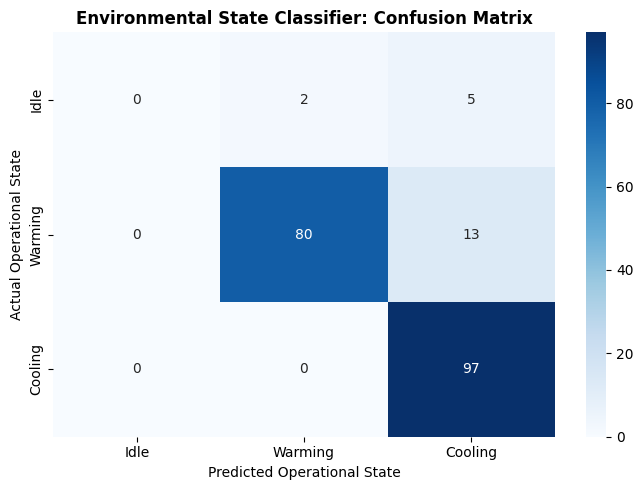

Confusion matrix plot saved and downloaded as 'classifier_confusion_matrix.png'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

In [3]:
# @title TRAIN TEST VALIDATE


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Run predictions on the test set using our trained classifier model
y_pred_probs = classifier.predict(X_test_c)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# 2. Print detailed classification report (Precision, Recall, F1-Score per state)
print("="*50)
print("    OMNINODE-AI CLASSIFIER VALIDATION REPORT")
print("="*50)
target_names = ['Stable / Idle (0)', 'Warming / Active (1)', 'Cooling / Ventilation (2)']
print(classification_report(y_test_c, y_pred_classes, target_names=target_names))
print("="*50)

# 3. Generate a Confusion Matrix visualization
conf_matrix = confusion_matrix(y_test_c, y_pred_classes)

plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Idle', 'Warming', 'Cooling'],
            yticklabels=['Idle', 'Warming', 'Cooling'])
plt.title('Environmental State Classifier: Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Operational State', fontsize=10)
plt.ylabel('Actual Operational State', fontsize=10)
plt.tight_layout()
plt.show()

# Save and download the confusion matrix plot
plot_filename = 'classifier_confusion_matrix.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')
print(f"Confusion matrix plot saved and downloaded as '{plot_filename}'!")
from google.colab import files
files.download(plot_filename)